# Logistic Regression: Base Model

CRISP-DM phase: Modelling + Evaluation

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the level (y)
X_train = train.drop('level', axis=1)
y_train = train['level']
X_test = test.drop('level', axis=1)
y_test = test['level']

## 2. Cross-Validation

In [4]:
#stratified 5-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Base model

In [5]:
#base model with all default settings
model_default = LogisticRegression()

In [6]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_default, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.88      0.90      0.89      9546
             1 mild       0.72      0.74      0.73      4827
2 moderate or worse       0.82      0.57      0.68      1027

           accuracy                           0.83     15400
          macro avg       0.81      0.74      0.77     15400
       weighted avg       0.83      0.83      0.83     15400



#### Observation

With all default settings, the model reaches a macro F1 of 0.77 and an accuracy of 83%. It does well on the two bigger levels, finding 90% of okay students and 74% of mild students. However, it finds only 57% of moderate or worse students, so about 440 of the 1,027 students who need help most are missed. Its precision for level 2 is high (82%), which means the model only predicts level 2 when it is very sure and misses many students as a result.

This happens because the levels are imbalanced: there are about nine okay students for every moderate or worse student, so the model leans towards the bigger levels. For a screening app, missing a student who needs help is the worst mistake, so the next step adds class weights to improve level 2 recall.

## 4. Iterations

In [7]:
#number of steps the model needed to finish learning
model_default.fit(X_train, y_train)
print(model_default.n_iter_)

[69]


The model is able to complete all learning in 69 steps, meaning the default 100 steps/iterations are more than enough to train the model.

## 5. Class Weights

In [8]:
#model with balanced class weights
model_balanced = LogisticRegression(class_weight='balanced')
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_balanced, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.92      0.83      0.87      9546
             1 mild       0.66      0.74      0.70      4827
2 moderate or worse       0.57      0.80      0.67      1027

           accuracy                           0.80     15400
          macro avg       0.72      0.79      0.75     15400
       weighted avg       0.82      0.80      0.80     15400



#### Observation

Adding balanced class weights raises the recall for level 2 from 57% to 80%, so the model now finds about four in five moderate or worse students, and the number of missed level 2 students falls from about 440 to about 205. The cost is more false alarms: precision for level 2 drops from 82% to 57%, and recall for okay students drops from 90% to 83% because more of them are now predicted as mild. Recall for mild students stays at 74%.

The overall macro F1 drops slightly (0.77 to 0.75) and so does accuracy (83% to 80%), but macro recall rises from 0.74 to 0.79. For a screening app, missing a student who needs help is worse than a false alarm, because a false alarm only suggests that a student talk to someone. We therefore keep the class weights for the rest of the notebook.

### 6. Choosing C

In [9]:
#cross-validation with C = 0.01 (strong regularisation)
model_001 = LogisticRegression(class_weight='balanced', C=0.01)
scores_001 = cross_val_score(model_001, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_001.round(3))
print(scores_001.mean().round(3), scores_001.std().round(3))

[0.73  0.758 0.743 0.742 0.738]
0.742 0.009


In [10]:
#cross-validation with C = 0.1
model_01 = LogisticRegression(class_weight='balanced', C=0.1)
scores_01 = cross_val_score(model_01, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_01.round(3))
print(scores_01.mean().round(3), scores_01.std().round(3))

[0.73  0.761 0.741 0.744 0.744]
0.744 0.01


In [11]:
#cross-validation with C = 1 (the default)
model_1 = LogisticRegression(class_weight='balanced')
scores_1 = cross_val_score(model_1, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_1.round(3))
print(scores_1.mean().round(3), scores_1.std().round(3))

[0.731 0.765 0.74  0.743 0.748]
0.745 0.011


In [12]:
#cross-validation with C = 10 (weak regularisation)
model_10 = LogisticRegression(class_weight='balanced', C=10)
scores_10 = cross_val_score(model_10, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_10.round(3))
print(scores_10.mean().round(3), scores_10.std().round(3))

[0.73  0.764 0.74  0.743 0.747]
0.745 0.011


In [13]:
#comparing the four values of C
cv_results = pd.DataFrame({'C': [0.01, 0.1, 1, 10],
                           'mean f1_macro': [scores_001.mean(), scores_01.mean(), scores_1.mean(), scores_10.mean()],
                           'std': [scores_001.std(), scores_01.std(), scores_1.std(), scores_10.std()]})
cv_results.round(4)

,C,mean f1_macro,std
0,0.01,0.7423,0.0092
1,0.10,0.7440,0.0100
2,1.00,0.7452,0.0112
3,10.00,0.7449,0.0111


#### Observation

The four values of C give almost the same mean macro F1 (0.742, 0.744, 0.745 and 0.745). The biggest difference between them (0.003) is smaller than the normal change between folds (a standard deviation of about 0.01), so the amount of regularisation makes no real difference to this model.

A small C could cause underfitting (the model is too restricted to learn the patterns) and a large C could cause overfitting (the model learns quirks of the training students that do not apply to new students).

C = 1 and C = 10 are tied for the best mean. We chose C = 1 because it is the default and there is no benefit in weakening the penalty further. Its fold scores (0.73 to 0.77) show the result is stable across folds.

## 7. Evaluation on the Test Set

### 7.1 Fitting the Final Base Model

After conducting all the previous tests, the best specs for the model were found to be default iteration value, default c value and setting class weight to balanced. The said specifications will be used for the final model on the test data

In [14]:
#fitting on the full training set and predicting the test set
model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

### 7.2 Classification Report

In [15]:
#per-class recall, precision and f1 on the test set
print(classification_report(y_test, y_pred, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.83      0.88      2387
             1 mild       0.66      0.73      0.70      1207
2 moderate or worse       0.53      0.78      0.64       257

           accuracy                           0.80      3851
          macro avg       0.71      0.78      0.74      3851
       weighted avg       0.82      0.80      0.80      3851



In [16]:
#macro f1 on the test set, to compare with the cross-validation score
print(round(f1_score(y_test, y_pred, average='macro'), 3))

0.736


#### Observation

On the test set the macro F1 is 0.736, close to the cross-validation score of 0.745, so the model is not overfitting the training data and the cross-validation was a good guide. The recall is 83% for level 0, 73% for level 1 and 78% for level 2, so the model finds about four in five moderate or worse students. The precision for level 2 is only 53%, which means that about half of the students the model flags as level 2 are really mild or okay. Predictions of level 0 are reliable (precision 93%). Level 2 has the lowest F1 (0.64) because it is the smallest and hardest level. The overall accuracy is 80%, but accuracy hides these differences between the levels, so per-class recall and macro F1 are the measures to follow. The class weights make the model find more level 2 students, and the lower precision is the cost of that.

### 7.3 Confusion Matrix

Each row is the true level and each column is the predicted level, so the numbers on the diagonal are correct predictions.

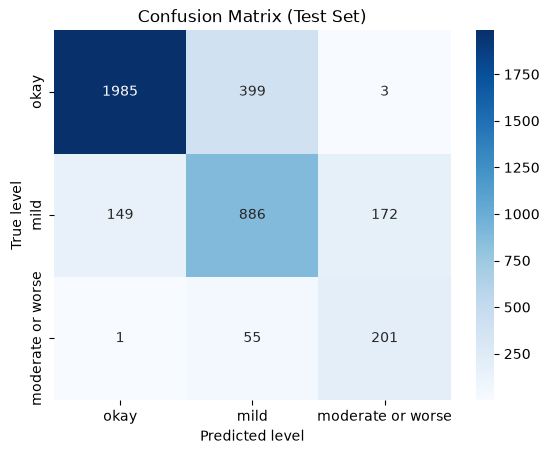

In [17]:
#confusion matrix of the test set
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

Of the 2,387 okay students, 1,985 are correct (83%), 399 are predicted mild and 3 are predicted level 2. Of the 1,207 mild students, 886 are correct (73%), 149 are predicted okay and 172 are predicted level 2. Of the 257 level 2 students, 201 are found (78%), 55 are predicted mild and only 1 is predicted okay. Almost all mistakes are between neighbouring levels: only 4 of the 3,851 students are two levels away (3 okay students predicted as level 2 and 1 level 2 student predicted as okay). Most of the false alarms for level 2 are mild students (172 of 175), and 55 of the 56 missed level 2 students were still predicted mild. The boundary between mild and moderate or worse is therefore the hardest one, which matches the overlap seen in the EDA.

## 8. Comparison with the PHQ-2 Baseline

The PHQ-2 rule (the first two PHQ-9 questions added up, positive when 3 or more) is a yes/no rule, so it is compared with the model only on finding level 2 (moderate or worse) against everyone else. The cells below use the same test set.

In [18]:
#phq-2 rule on the test set: score of 3 or more = possible level 2
phq2_pred = (X_test['phq_q1'] + X_test['phq_q2']) >= 3

In [19]:
#level 2 recall and precision for the phq-2 rule and for the model
comparison = pd.DataFrame({'method': ['PHQ-2 rule', 'Logistic regression'],
                           'level 2 recall': [recall_score(y_test == 2, phq2_pred), recall_score(y_test == 2, y_pred == 2)],
                           'level 2 precision': [precision_score(y_test == 2, phq2_pred), precision_score(y_test == 2, y_pred == 2)]})
comparison.round(3)

,method,level 2 recall,level 2 precision
0,PHQ-2 rule,0.638,0.636
1,Logistic regression,0.782,0.535


#### Observation

On the test set the PHQ-2 rule finds 63.8% of level 2 students (164 of 257) with a precision of 63.6%. The logistic regression model finds 78.2% (201 of 257), which is 37 more students, but its precision is lower at 53.5%. It raises 175 false alarms against 94 for the PHQ-2 rule (81 more), and almost all of them are mild students. So the model beats the baseline on the main aim, recall for level 2, at the price of lower precision. It also does something the rule cannot do, which is to separate level 0 from level 1 (recall 83% and 73%). Whether the extra false alarms are acceptable is a decision for the app: a false alarm means a student is encouraged to look for support they may not need, while a missed case means a student gets no prompt at all.

## 9. Summary of the Base Model

- **Base model:** logistic regression with `class_weight='balanced'` and `C = 1`, trained on the 21 selected questions to predict level 0 (okay), 1 (mild) or 2 (moderate or worse). The PHQ-9 total and questions 3 to 9 are not features.
- **Validity:** stratified 5-fold cross-validation on the training set gave a macro F1 of 0.745 (standard deviation 0.011), and the choice of `C` made almost no difference. The held-out test set gave a macro F1 of 0.736, so the two agree.
- **Per-class results on the test set:** recall of 83% (okay), 73% (mild) and 78% (moderate or worse), with a precision of 53% for level 2. Almost all mistakes are between neighbouring levels.
- **Against the PHQ-2 rule:** the model finds more level 2 students (78% against 64%) but raises more false alarms (precision 53% against 64%).
- **Limits:** the test set has only 257 level 2 students, mild against moderate or worse is the hardest split, and the questions were selected using all students before the split.

The next step is to compare this base model with other models on the same data (Section 7).